In [2]:
# Requires: pip install cvxpy numpy
import numpy as np
import cvxpy as cp

def make_grid(d: int, include_endpoints: bool = False) -> np.ndarray:
    """
    Grid on [-1,1].
    - include_endpoints=False: d interior points, avoids division-by-zero in u_{a,b}.
    - include_endpoints=True: includes -1 and 1, can create degeneracies in u_{a,b}.
    """
    if include_endpoints:
        return np.linspace(-1.0, 1.0, d)
    # d interior points: linspace with d+2 points, drop endpoints
    return np.linspace(-1.0, 1.0, d + 2)[1:-1]

def u_ab(x: np.ndarray, a: int, b: int) -> np.ndarray:
    """
    Extreme point u_{a,b} evaluated on grid x.
    a,b are 0-indexed with 0 <= a <= b <= d-1.

    Corrected piecewise definition (in terms of x_i, not i):
      for i <= a:      1 - (x_i+1)/(x_a+1)
      for a < i < b:   0
      for i >= b:      (x_i - x_b)/(1 - x_b)

    This matches the “V” / “V-with-flat-bottom” shape built from chords
    (-1,1)->(x_a,0) and (x_b,0)->(1,1).
    """
    d = len(x)
    xa, xb = x[a], x[b]
    v = np.zeros(d)
    for i in range(d):
        if i <= a:
            v[i] = 1.0 - (x[i] + 1.0) / (xa + 1.0)
        elif i < b:
            v[i] = 0.0
        else:
            v[i] = (x[i] - xb) / (1.0 - xb)
    # small numerical cleanup
    return np.clip(v, 0.0, 1.0)

def extreme_points(d: int, include_endpoints: bool = False):
    x = make_grid(d, include_endpoints=include_endpoints)
    verts = []
    for a in range(d):
        for b in range(a, d):
            verts.append((a, b, u_ab(x, a, b)))
    return x, verts

def solve_minmax(d: int = 4,
                 C: float = 1.0,
                 include_endpoints: bool = False,
                 impose_zero_mean_columns: bool = True,
                 solver: str = "SCS",
                 verbose: bool = False):
    """
    Solves:
      minimize_{S,B}  max_{(a,b)} [ C * max_k <u-e_k, r_{a,b}> + (1/d^2) sum_i || v_i s_i + b_i ||^2 ]
    where r_{a,b} = (I - S/d) v - (1/d) sum_j b_j.

    Returns S,B and the achieved objective.
    """
    x, verts = extreme_points(d, include_endpoints=include_endpoints)

    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    # decision variables
    S = cp.Variable((d, d))  # columns s_i
    B = cp.Variable((d, d))  # columns b_i
    t = cp.Variable()        # epigraph for worst-case objective

    # average intercept vector \bar b = (1/d) sum_i b_i = (1/d) B 1
    bar_b = (1.0 / d) * (B @ ones)

    constraints = [t >= 0]

    # WLOG constraint that avoids wasting variance on constant components
    # (safe because the bias directions u-e_k are mean-zero)
    if impose_zero_mean_columns:
        constraints += [
            ones @ S == np.zeros(d),  # 1^T s_i = 0 for each column
            ones @ B == np.zeros(d),  # 1^T b_i = 0 for each column
        ]

    for (a, b, v) in verts:
        theta = cp.Variable()  # epigraph for bias on this vertex

        # r(v) = (I - S/d) v - \bar b
        r = (I - (1.0 / d) * S) @ v - bar_b

        # theta >= max_k <u - e_k, r>
        for k in range(d):
            w = u.copy()
            w[k] -= 1.0
            constraints += [theta >= w @ r]

        # variance(v) = (1/d^2) sum_i || v_i s_i + b_i ||^2
        var = 0
        for i in range(d):
            var += cp.sum_squares(v[i] * S[:, i] + B[:, i])
        var = var / (d ** 2)

        # t dominates this vertex's total
        constraints += [t >= C * theta + var]

    prob = cp.Problem(cp.Minimize(t), constraints)
    prob.solve(solver=solver, verbose=verbose)

    return {
        "status": prob.status,
        "opt_value": prob.value,
        "S": S.value,
        "B": B.value,
        "x": x,
        "verts": verts,
        "C": C,
        "include_endpoints": include_endpoints,
        "zero_mean_cols": impose_zero_mean_columns,
    }

def evaluate_solution(sol):
    S = sol["S"]
    B = sol["B"]
    C = sol["C"]
    verts = sol["verts"]

    d = S.shape[0]
    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d
    allow = np.eye(d)

    bar_b = (B @ ones) / d

    worst_val = -1e300
    worst_ab = None
    worst_bias = None
    worst_var = None

    for (a, b, v) in verts:
        r = (I - S / d) @ v - bar_b
        bias = max([(u - allow[k]) @ r for k in range(d)])
        var = sum(np.linalg.norm(v[i] * S[:, i] + B[:, i]) ** 2 for i in range(d)) / (d ** 2)
        val = C * bias + var
        if val > worst_val:
            worst_val = val
            worst_ab = (a, b)
            worst_bias = bias
            worst_var = var

    return {
        "worst_value": worst_val,
        "worst_a_b_1indexed": (worst_ab[0] + 1, worst_ab[1] + 1),
        "worst_bias": worst_bias,
        "worst_variance": worst_var,
    }

if __name__ == "__main__":
    d = 4
    C = 4

    sol = solve_minmax(d=d, C=C, include_endpoints=False,
                       impose_zero_mean_columns=True,
                       solver="SCS", verbose=False)

    print("status:", sol["status"])
    print("optimal worst-case objective t*:", sol["opt_value"])
    print("\nS* =")
    print(sol["S"])
    print("\nB* =")
    print(sol["B"])

    stats = evaluate_solution(sol)
    print("\nWorst-case vertex (a,b) (1-indexed):", stats["worst_a_b_1indexed"])
    print("Worst-case value:", stats["worst_value"])
    print("  bias part:", stats["worst_bias"])
    print("  variance part:", stats["worst_variance"])

    # Optional: check scaling vs d for fixed C (expect O(1) behavior).
    # for d in range(2, 11):
    #     sol_d = solve_minmax(d=d, C=C, include_endpoints=False,
    #                          impose_zero_mean_columns=True,
    #                          solver="SCS", verbose=False)
    #     print(d, sol_d["opt_value"])


status: optimal
optimal worst-case objective t*: 0.2244443233601096

S* =
[[ 2.69345583 -0.28933123 -1.50862103 -0.90012022]
 [-0.89322627  2.88865934 -1.09070708 -0.90010934]
 [-0.90010934 -1.09070708  2.88865934 -0.89322627]
 [-0.90012022 -1.50862103 -0.28933123  2.69345583]]

B* =
[[-0.89565664  0.12348593  0.39605263  0.37784906]
 [ 0.25768423 -0.70443511  0.18489655  0.26012335]
 [ 0.26012335  0.18489655 -0.70443511  0.25768423]
 [ 0.37784906  0.39605263  0.12348593 -0.89565664]]

Worst-case vertex (a,b) (1-indexed): (2, 3)
Worst-case value: 0.22447243115256527
  bias part: 0.025400301537239767
  variance part: 0.12287122500360619


In [3]:
# visualize the solution
import matplotlib.pyplot as plt

def plot_solution(sol):
    S = sol["S"]
    B = sol["B"]
    x = sol["x"]
    verts = sol["verts"]

    d = S.shape[0]
    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    bar_b = (B @ ones) / d

    plt.figure(figsize=(10, 6))

    for (a, b, v) in verts:
        r = (I - S / d) @ v - bar_b
        bias = max([(u - np.eye(d)[k]) @ r for k in range(d)])
        var = sum(np.linalg.norm(v[i] * S[:, i] + B[:, i]) ** 2 for i in range(d)) / (d ** 2)
        val = sol["C"] * bias + var

        plt.plot(x, v, label=f"(a={a+1},b={b+1}), val={val:.4f}")

    plt.title("Extreme Points and Their Values")
    plt.xlabel("x")
    plt.ylabel("v(x)")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()
    plt.show()

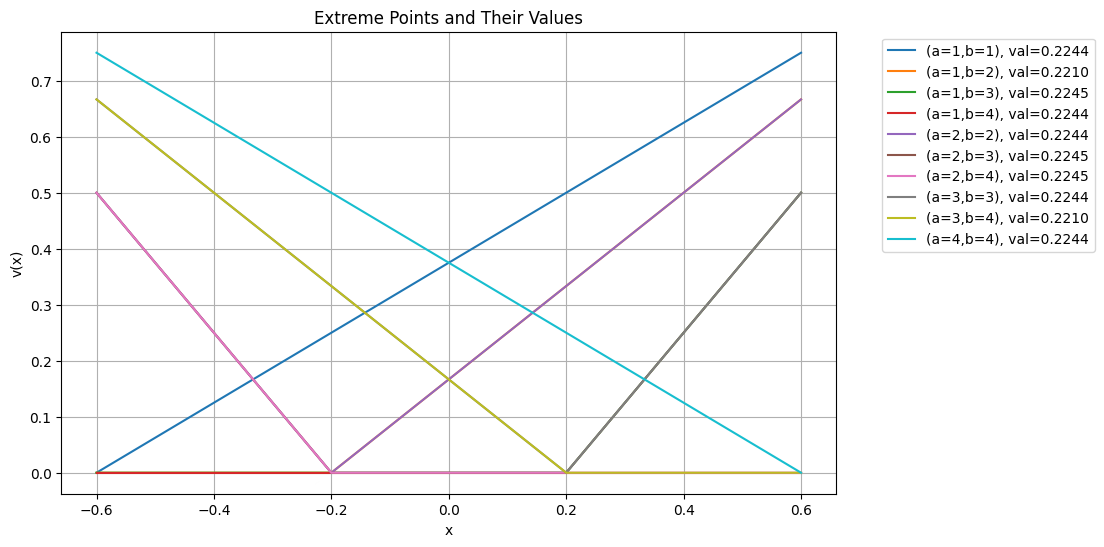

In [4]:
plot_solution(sol)

status: optimal
optimal worst-case objective t*: 0.176056981313728

S* =
 [[ 1.94492124  0.30991337 -1.92978458 -0.69053059]
 [-0.56978625  2.63768066 -1.01780944 -0.6846044 ]
 [-0.6846044  -1.01780944  2.63768066 -0.56978625]
 [-0.69053059 -1.92978458  0.30991337  1.94492124]]

B* =
 [[-0.75077067 -0.01688578  0.45641158  0.33242256]
 [ 0.18557838 -0.60600788  0.16648208  0.23276973]
 [ 0.23276973  0.16648208 -0.60600788  0.18557838]
 [ 0.33242256  0.45641158 -0.01688578 -0.75077067]]

Worst-case vertex (a,b) (1-indexed): (1, 4)
Worst-case achieved value: 0.17608703993693278
  bias part: 0.005294422878837163
  variance part: 0.17079261705809562


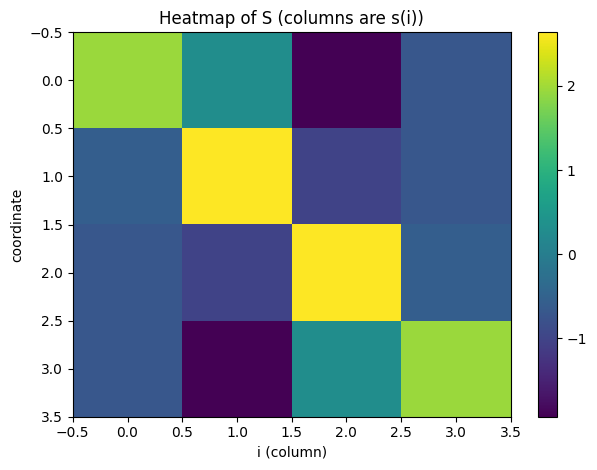

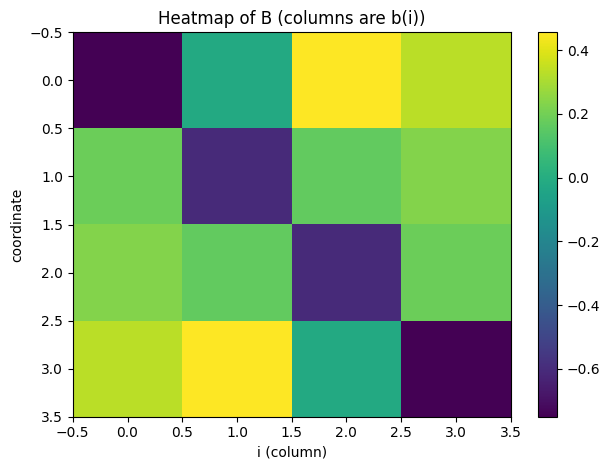

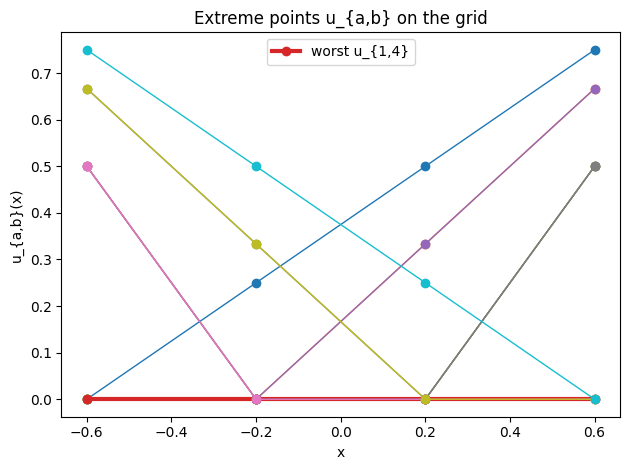

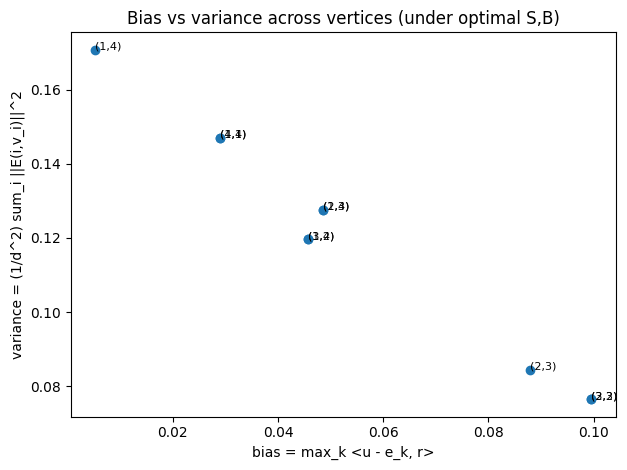

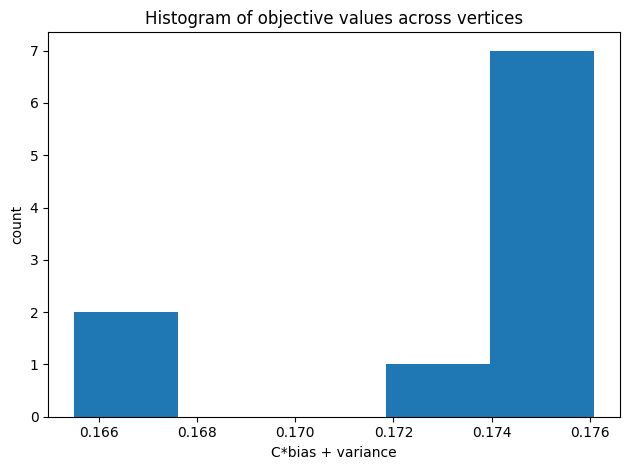

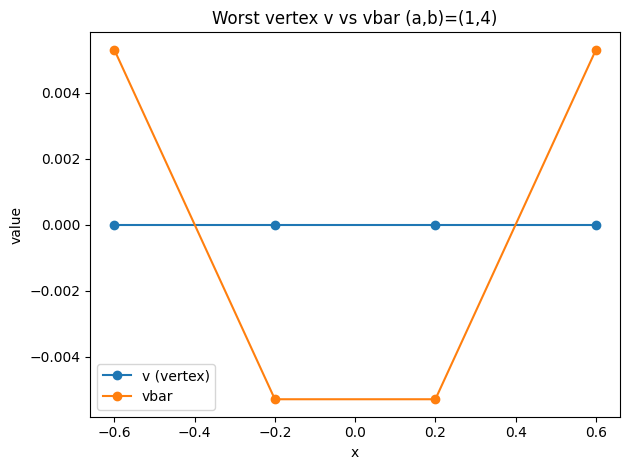

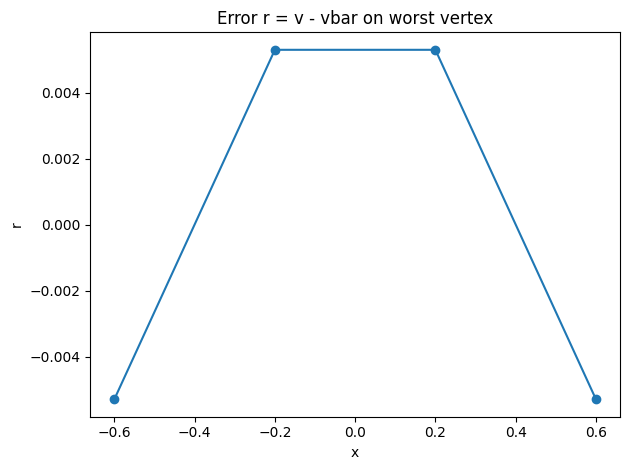

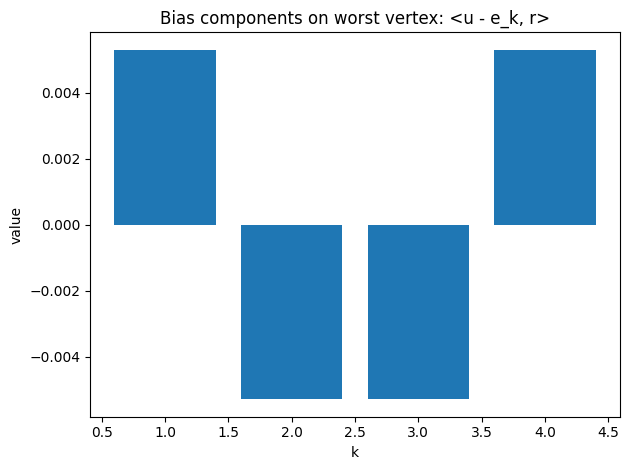

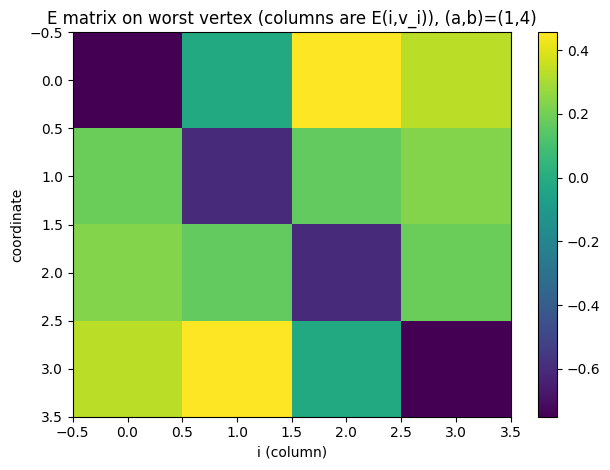

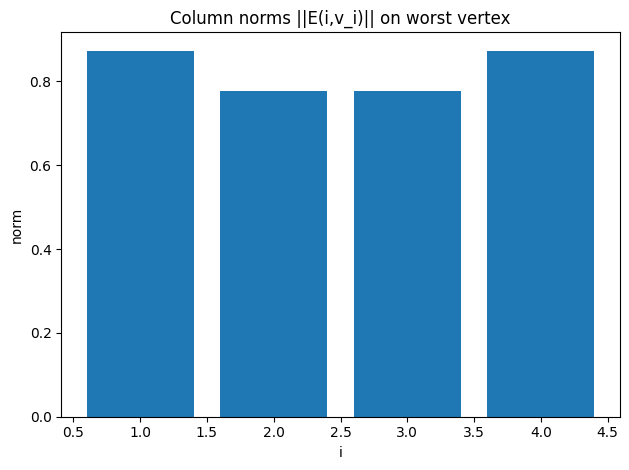

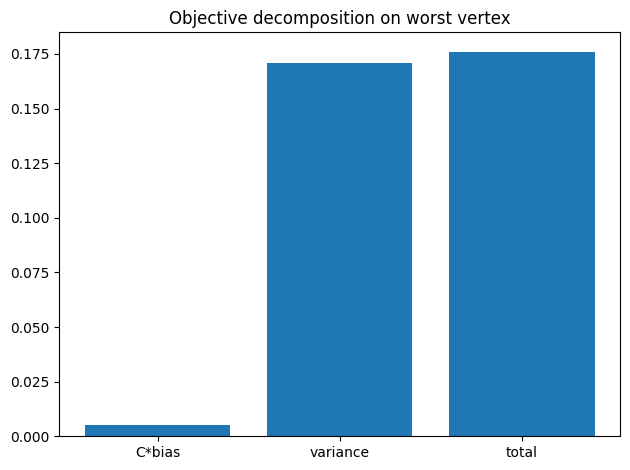

In [1]:
# Requires: pip install cvxpy numpy matplotlib
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt

def make_grid(d: int, include_endpoints: bool = False) -> np.ndarray:
    """
    Grid on [-1,1].
    - include_endpoints=False: d interior points, avoids division-by-zero in u_{a,b}.
    - include_endpoints=True: includes -1 and 1, can create degeneracies in u_{a,b}.
    """
    if include_endpoints:
        return np.linspace(-1.0, 1.0, d)
    return np.linspace(-1.0, 1.0, d + 2)[1:-1]

def u_ab(x: np.ndarray, a: int, b: int) -> np.ndarray:
    """
    Extreme point u_{a,b} evaluated on grid x.
    a,b are 0-indexed with 0 <= a <= b <= d-1.

    Piecewise definition (in terms of x_i):
      for i <= a:      1 - (x_i+1)/(x_a+1)
      for a < i < b:   0
      for i >= b:      (x_i - x_b)/(1 - x_b)

    Includes safe handling when x_a=-1 or x_b=1 (degenerate chords).
    """
    d = len(x)
    xa, xb = x[a], x[b]
    v = np.zeros(d)

    eps = 1e-12
    for i in range(d):
        if i <= a:
            denom = xa + 1.0
            if abs(denom) < eps:
                # Degenerate: chord from (-1,1) to (-1,0); only defines value 0 at x=-1
                v[i] = 0.0
            else:
                v[i] = 1.0 - (x[i] + 1.0) / denom
        elif i < b:
            v[i] = 0.0
        else:
            denom = 1.0 - xb
            if abs(denom) < eps:
                # Degenerate: chord from (1,0) to (1,1); only defines value 0 at x=1
                v[i] = 0.0
            else:
                v[i] = (x[i] - xb) / denom

    return np.clip(v, 0.0, 1.0)

def extreme_points(d: int, include_endpoints: bool = False):
    x = make_grid(d, include_endpoints=include_endpoints)
    verts = []
    for a in range(d):
        for b in range(a, d):
            verts.append((a, b, u_ab(x, a, b)))
    return x, verts

def solve_minmax(d: int = 4,
                 C: float = 1.0,
                 include_endpoints: bool = False,
                 impose_zero_mean_columns: bool = True,
                 solver: str = "SCS",
                 verbose: bool = False):
    """
    Convex QCQP:
      minimize_{S,B}  max_{(a,b)} [ C * max_k <u-e_k, r(v)> + (1/d^2) sum_i || v_i s_i + b_i ||^2 ]
    where r(v) = (I - S/d) v - (1/d) sum_j b_j.

    Returns a dict with S,B and metadata.
    """
    x, verts = extreme_points(d, include_endpoints=include_endpoints)

    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    S = cp.Variable((d, d))  # columns s_i
    B = cp.Variable((d, d))  # columns b_i
    t = cp.Variable()        # epigraph

    bar_b = (1.0 / d) * (B @ ones)

    constraints = [t >= 0]

    if impose_zero_mean_columns:
        constraints += [
            ones @ S == np.zeros(d),  # 1^T s_i = 0 for each column
            ones @ B == np.zeros(d),  # 1^T b_i = 0 for each column
        ]

    for (a, b, v) in verts:
        theta = cp.Variable()

        r = (I - (1.0 / d) * S) @ v - bar_b

        for k in range(d):
            w = u.copy()
            w[k] -= 1.0
            constraints += [theta >= w @ r]

        var = 0
        for i in range(d):
            var += cp.sum_squares(v[i] * S[:, i] + B[:, i])
        var = var / (d ** 2)

        constraints += [t >= C * theta + var]

    prob = cp.Problem(cp.Minimize(t), constraints)
    prob.solve(solver=solver, verbose=verbose)

    return {
        "status": prob.status,
        "opt_value": prob.value,
        "S": S.value,
        "B": B.value,
        "x": x,
        "verts": verts,
        "C": C,
        "include_endpoints": include_endpoints,
        "zero_mean_cols": impose_zero_mean_columns,
        "solver": solver,
    }

def evaluate_solution(sol):
    S = sol["S"]
    B = sol["B"]
    C = sol["C"]
    verts = sol["verts"]

    d = S.shape[0]
    I = np.eye(d)
    ones = np.ones(d)
    u = ones / d

    bar_b = (B @ ones) / d

    rows = []
    worst_val = -1e300
    worst = None

    for (a, b, v) in verts:
        vbar = (S @ v) / d + bar_b
        r = v - vbar
        bias_components = np.array([(u - np.eye(d)[k]) @ r for k in range(d)])
        bias = bias_components.max()

        E_mat = S @ np.diag(v) + B
        var = np.sum(np.linalg.norm(E_mat, axis=0) ** 2) / (d ** 2)

        val = C * bias + var
        rows.append({
            "a": a, "b": b,
            "bias": bias,
            "var": var,
            "obj": val,
            "v": v,
            "vbar": vbar,
            "r": r,
            "bias_components": bias_components,
            "E_mat": E_mat,
        })
        if val > worst_val:
            worst_val = val
            worst = rows[-1]

    return {
        "rows": rows,
        "worst": worst,
        "worst_value": worst_val,
        "worst_a_b_1indexed": (worst["a"] + 1, worst["b"] + 1),
    }

def plot_heatmap(A, title, xlabel="column", ylabel="row"):
    plt.figure()
    plt.imshow(A, aspect="auto")
    plt.colorbar()
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()

def plot_vertices(x, verts, worst_ab=None):
    """
    Plots all u_{a,b} as curves vs x. If worst_ab given (0-indexed tuple),
    highlight it by thicker line.
    """
    plt.figure()
    for (a, b, v) in verts:
        if worst_ab is not None and (a, b) == worst_ab:
            plt.plot(x, v, marker="o", linewidth=3, label=f"worst u_{{{a+1},{b+1}}}")
        else:
            plt.plot(x, v, marker="o", linewidth=1)
    plt.title("Extreme points u_{a,b} on the grid")
    plt.xlabel("x")
    plt.ylabel("u_{a,b}(x)")
    if worst_ab is not None:
        plt.legend()
    plt.tight_layout()

def plot_bias_variance_scatter(rows):
    biases = np.array([r["bias"] for r in rows])
    vars_ = np.array([r["var"] for r in rows])
    objs = np.array([r["obj"] for r in rows])

    plt.figure()
    plt.scatter(biases, vars_)
    for i, r in enumerate(rows):
        plt.annotate(f"({r['a']+1},{r['b']+1})", (biases[i], vars_[i]), fontsize=8)
    plt.title("Bias vs variance across vertices (under optimal S,B)")
    plt.xlabel("bias = max_k <u - e_k, r>")
    plt.ylabel("variance = (1/d^2) sum_i ||E(i,v_i)||^2")
    plt.tight_layout()

    plt.figure()
    plt.hist(objs, bins=max(5, len(objs)//2))
    plt.title("Histogram of objective values across vertices")
    plt.xlabel("C*bias + variance")
    plt.ylabel("count")
    plt.tight_layout()

def plot_worst_case_details(x, worst, C):
    v = worst["v"]
    vbar = worst["vbar"]
    r = worst["r"]
    bias_components = worst["bias_components"]
    E_mat = worst["E_mat"]

    a, b = worst["a"], worst["b"]
    d = len(v)

    plt.figure()
    plt.plot(x, v, marker="o", label="v (vertex)")
    plt.plot(x, vbar, marker="o", label="vbar")
    plt.title(f"Worst vertex v vs vbar (a,b)=({a+1},{b+1})")
    plt.xlabel("x")
    plt.ylabel("value")
    plt.legend()
    plt.tight_layout()

    plt.figure()
    plt.plot(x, r, marker="o")
    plt.title("Error r = v - vbar on worst vertex")
    plt.xlabel("x")
    plt.ylabel("r")
    plt.tight_layout()

    plt.figure()
    plt.bar(np.arange(1, d+1), bias_components)
    plt.title("Bias components on worst vertex: <u - e_k, r>")
    plt.xlabel("k")
    plt.ylabel("value")
    plt.tight_layout()

    # Show E matrix (columns are E(i,v_i))
    plot_heatmap(E_mat, f"E matrix on worst vertex (columns are E(i,v_i)), (a,b)=({a+1},{b+1})",
                 xlabel="i (column)", ylabel="coordinate")

    # Column norms of E(i,v_i)
    col_norms = np.linalg.norm(E_mat, axis=0)
    plt.figure()
    plt.bar(np.arange(1, d+1), col_norms)
    plt.title("Column norms ||E(i,v_i)|| on worst vertex")
    plt.xlabel("i")
    plt.ylabel("norm")
    plt.tight_layout()

    # Decompose objective terms
    bias = worst["bias"]
    var = worst["var"]
    plt.figure()
    plt.bar(["C*bias", "variance", "total"], [C*bias, var, C*bias + var])
    plt.title("Objective decomposition on worst vertex")
    plt.tight_layout()

def visualize_solution(sol, stats, save_prefix=None, show=True):
    S = sol["S"]
    B = sol["B"]
    x = sol["x"]
    verts = sol["verts"]
    C = sol["C"]

    worst = stats["worst"]
    worst_ab = (worst["a"], worst["b"])

    plot_heatmap(S, "Heatmap of S (columns are s(i))", xlabel="i (column)", ylabel="coordinate")
    plot_heatmap(B, "Heatmap of B (columns are b(i))", xlabel="i (column)", ylabel="coordinate")

    plot_vertices(x, verts, worst_ab=worst_ab)
    plot_bias_variance_scatter(stats["rows"])
    plot_worst_case_details(x, worst, C)

    if save_prefix is not None:
        for i, fig_num in enumerate(plt.get_fignums(), start=1):
            fig = plt.figure(fig_num)
            fig.savefig(f"{save_prefix}_{i:02d}.png", dpi=200, bbox_inches="tight")

    if show:
        plt.show()

if __name__ == "__main__":
    d = 4
    C = 1.0

    sol = solve_minmax(
        d=d,
        C=C,
        include_endpoints=False,          # safer numerically
        impose_zero_mean_columns=True,    # WLOG; reduces variance waste
        solver="SCS",
        verbose=False
    )

    print("status:", sol["status"])
    print("optimal worst-case objective t*:", sol["opt_value"])
    print("\nS* =\n", sol["S"])
    print("\nB* =\n", sol["B"])

    stats = evaluate_solution(sol)
    print("\nWorst-case vertex (a,b) (1-indexed):", stats["worst_a_b_1indexed"])
    print("Worst-case achieved value:", stats["worst_value"])
    print("  bias part:", stats["worst"]["bias"])
    print("  variance part:", stats["worst"]["var"])

    # Visualize. To save instead, set save_prefix="out/d4_C1" and show=False.
    visualize_solution(sol, stats, save_prefix=None, show=True)


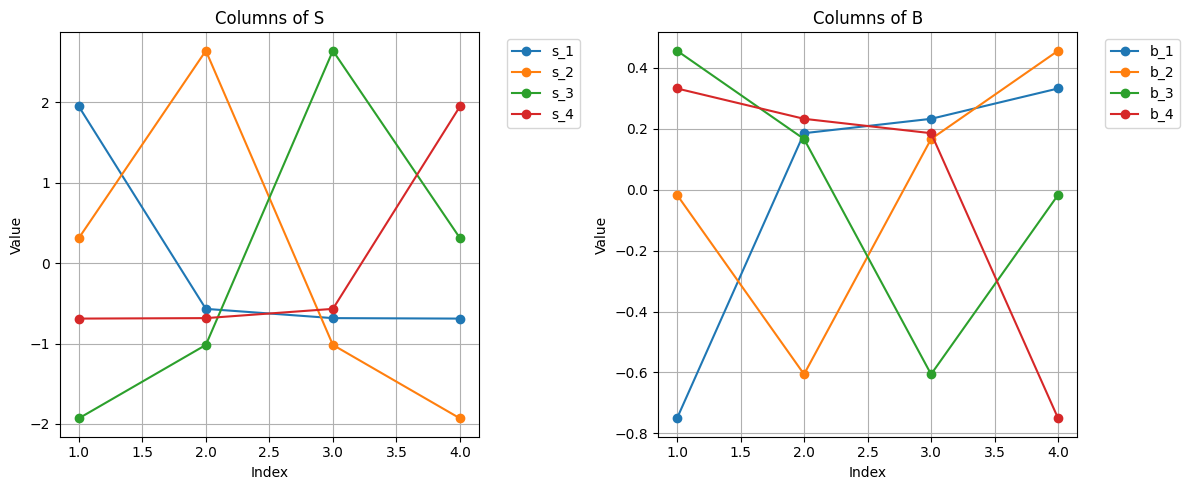

In [2]:
# plot each column of S and B as a function of index
def plot_S_B_columns(sol):
    S = sol["S"]
    B = sol["B"]
    d = S.shape[0]
    indices = np.arange(1, d + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    for i in range(d):
        plt.plot(indices, S[:, i], marker='o', label=f's_{i+1}')
    plt.title('Columns of S')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.subplot(1, 2, 2)
    for i in range(d):
        plt.plot(indices, B[:, i], marker='o', label=f'b_{i+1}')
    plt.title('Columns of B')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.tight_layout()
    plt.show()
plot_S_B_columns(sol)

In [1]:

# new one on Jan 28
import numpy as np
import cvxpy as cp

def make_interior_grid(d):
    # x_i = -1 + 2*(i+1)/(d+1), i=0..d-1
    i = np.arange(1, d+1)
    return -1.0 + 2.0 * i / (d + 1.0)

def precompute_lr_coeffs(x):
    """
    Precompute left vectors ell[a] and right vectors rr[b] such that
      u_{a,b} = ell[a] + rr[b]  for a<=b
    using:
      ell[a]_i = 1 - (x_i+1)/(x_a+1)  if i<a else 0
      rr[b]_i  = (x_i-x_b)/(1-x_b)    if i>b else 0
    Indices are 0-based in code, but correspond to 1..d in math.
    """
    d = len(x)
    ell = []
    rr = []

    for a in range(d):
        v = np.zeros(d)
        if a > 0:
            # i<a => i=0..a-1
            v[:a] = 1.0 - (x[:a] + 1.0) / (x[a] + 1.0)
        ell.append(v)

    for b in range(d):
        v = np.zeros(d)
        if b < d-1:
            # i>b => i=b+1..d-1
            v[b+1:] = (x[b+1:] - x[b]) / (1.0 - x[b])
        rr.append(v)

    return ell, rr

def solve_structured_socp(d=30, C=1.0, zero_mean_cols=True, solver="ECOS", verbose=False):
    x = make_interior_grid(d)
    ell, rr = precompute_lr_coeffs(x)

    ones = np.ones(d)

    # Variables
    S = cp.Variable((d, d))      # columns s_i
    B = cp.Variable((d, d))      # columns b_i
    t = cp.Variable()            # worst-case objective

    # Variance aggregation variables
    L = cp.Variable(d)           # L[a] >= sum_{i<a} || ell[a]_i s_i + b_i ||^2
    R = cp.Variable(d)           # R[b] >= sum_{i>b} || rr[b]_i  s_i + b_i ||^2
    p = cp.Variable(d)           # p[i] >= ||b_i||^2
    P = cp.Variable(d+1)         # prefix sums of p

    constraints = [t >= 0]

    # WLOG: remove constant components from columns (helps variance, doesn't hurt your bias directions)
    if zero_mean_cols:
        constraints += [ones @ S == 0, ones @ B == 0]

    # bar_b = (1/d) sum_i b_i
    bar_b = (B @ ones) / d

    # Prefix sums for middle block
    constraints += [P[0] == 0]
    for i in range(d):
        constraints += [P[i+1] == P[i] + p[i]]

    # p[i] epigraph
    for i in range(d):
        constraints += [p[i] >= cp.sum_squares(B[:, i])]

    # Left variance L[a]
    constraints += [L[0] == 0]
    for a in range(1, d):
        alpha = ell[a][:a]  # length a
        # columns 0..a-1 contribute
        X = cp.multiply(alpha, S[:, :a]) + B[:, :a]   # broadcast alpha across rows
        constraints += [L[a] >= cp.sum_squares(X)]

    # Right variance R[b]
    constraints += [R[d-1] == 0]
    for b in range(d-1):
        beta = rr[b][b+1:]  # length d-(b+1)
        X = cp.multiply(beta, S[:, b+1:]) + B[:, b+1:]
        constraints += [R[b] >= cp.sum_squares(X)]

    # Precompute reusable expressions for bias: S@ell[a] and S@rr[b]
    # These are affine expressions, not new variables.
    Sell = [S @ ell[a] for a in range(d)]
    Srr  = [S @ rr[b]  for b in range(d)]

    # Main robust constraints over all (a,b)
    # bias(a,b) = max_k (mean(r_ab) - (r_ab)_k)
    for a in range(d):
        for b in range(a, d):
            u_ab = ell[a] + rr[b]   # constant numpy vector
            u_ab_c = cp.Constant(u_ab)

            # r_ab = (I - S/d) u_ab - bar_b = u_ab - (S u_ab)/d - bar_b
            Su = Sell[a] + Srr[b]
            r_ab = u_ab_c - (Su / d) - bar_b

            mean_r = cp.sum(r_ab) / d
            # introduce theta implicitly by pushing constraints into t directly
            # t >= C*(mean_r - r_ab[k]) + var_ab  for all k
            var_ab = (L[a] + (P[b+1] - P[a]) + R[b]) / (d**2)

            for k in range(d):
                constraints += [t >= C * (mean_r - r_ab[k]) + var_ab]

    prob = cp.Problem(cp.Minimize(t), constraints)
    prob.solve(solver=solver, verbose=verbose)

    return {
        "status": prob.status,
        "t": prob.value,
        "S": None if S.value is None else S.value.copy(),
        "B": None if B.value is None else B.value.copy(),
        "x": x,
    }

sol = solve_structured_socp(d=30, C=30.0, zero_mean_cols=True, solver="ECOS", verbose=False)
print("status:", sol["status"])
print("t*:", sol["t"])


/var/folders/2y/8rqh7kk566b1nf_453g9hx3w0000gn/T/ipykernel_569/88419521.py:114: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=solver, verbose=verbose)
/var/folders/2y/8rqh7kk566b1nf_453g9hx3w0000gn/T/ipykernel_569/88419521.py:114: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  prob.solve(solver=solver, verbose=verbose)


status: optimal_inaccurate
t*: 1.26952691462779


In [2]:

# new one on Jan 28
import numpy as np
import cvxpy as cp

def make_interior_grid(d):
    # x_i = -1 + 2*(i+1)/(d+1), i=0..d-1
    i = np.arange(1, d+1)
    return -1.0 + 2.0 * i / (d + 1.0)

def precompute_lr_coeffs(x):
    """
    Precompute left vectors ell[a] and right vectors rr[b] such that
      u_{a,b} = ell[a] + rr[b]  for a<=b
    using:
      ell[a]_i = 1 - (x_i+1)/(x_a+1)  if i<a else 0
      rr[b]_i  = (x_i-x_b)/(1-x_b)    if i>b else 0
    Indices are 0-based in code, but correspond to 1..d in math.
    """
    d = len(x)
    ell = []
    rr = []

    for a in range(d):
        v = np.zeros(d)
        if a > 0:
            # i<a => i=0..a-1
            v[:a] = 1.0 - (x[:a] + 1.0) / (x[a] + 1.0)
        ell.append(v)

    for b in range(d):
        v = np.zeros(d)
        if b < d-1:
            # i>b => i=b+1..d-1
            v[b+1:] = (x[b+1:] - x[b]) / (1.0 - x[b])
        rr.append(v)

    return ell, rr

def solve_structured_socp(d=30, C=1.0, zero_mean_cols=True, solver="ECOS", verbose=False):
    x = make_interior_grid(d)
    ell, rr = precompute_lr_coeffs(x)

    ones = np.ones(d)

    # Variables
    S = cp.Variable((d, d))      # columns s_i
    B = cp.Variable((d, d))      # columns b_i
    t = cp.Variable()            # worst-case objective

    # Variance aggregation variables
    L = cp.Variable(d)           # L[a] >= sum_{i<a} || ell[a]_i s_i + b_i ||^2
    R = cp.Variable(d)           # R[b] >= sum_{i>b} || rr[b]_i  s_i + b_i ||^2
    p = cp.Variable(d)           # p[i] >= ||b_i||^2
    P = cp.Variable(d+1)         # prefix sums of p

    constraints = [t >= 0]

    # WLOG: remove constant components from columns (helps variance, doesn't hurt your bias directions)
    if zero_mean_cols:
        constraints += [ones @ S == 0, ones @ B == 0]

    # bar_b = (1/d) sum_i b_i
    bar_b = (B @ ones) / d

    # Prefix sums for middle block
    constraints += [P[0] == 0]
    for i in range(d):
        constraints += [P[i+1] == P[i] + p[i]]

    # p[i] epigraph
    for i in range(d):
        constraints += [p[i] >= cp.sum_squares(B[:, i])]

    # Left variance L[a]
    constraints += [L[0] == 0]
    for a in range(1, d):
        alpha = ell[a][:a]  # length a
        # columns 0..a-1 contribute
        X = cp.multiply(alpha, S[:, :a]) + B[:, :a]   # broadcast alpha across rows
        constraints += [L[a] >= cp.sum_squares(X)]

    # Right variance R[b]
    constraints += [R[d-1] == 0]
    for b in range(d-1):
        beta = rr[b][b+1:]  # length d-(b+1)
        X = cp.multiply(beta, S[:, b+1:]) + B[:, b+1:]
        constraints += [R[b] >= cp.sum_squares(X)]

    # Precompute reusable expressions for bias: S@ell[a] and S@rr[b]
    # These are affine expressions, not new variables.
    Sell = [S @ ell[a] for a in range(d)]
    Srr  = [S @ rr[b]  for b in range(d)]

    # Main robust constraints over all (a,b)
    # bias(a,b) = max_k (mean(r_ab) - (r_ab)_k)
    for a in range(d):
        for b in range(a, d):
            u_ab = ell[a] + rr[b]   # constant numpy vector
            u_ab_c = cp.Constant(u_ab)

            # r_ab = (I - S/d) u_ab - bar_b = u_ab - (S u_ab)/d - bar_b
            Su = Sell[a] + Srr[b]
            r_ab = u_ab_c - (Su / d) - bar_b

            mean_r = cp.sum(r_ab) / d
            # introduce theta implicitly by pushing constraints into t directly
            # t >= C*(mean_r - r_ab[k]) + var_ab  for all k
            var_ab = (L[a] + (P[b+1] - P[a]) + R[b]) / (d**2)

            for k in range(d):
                constraints += [t >= C * (mean_r - r_ab[k]) + var_ab]

    prob = cp.Problem(cp.Minimize(t), constraints)
    prob.solve(solver=solver, verbose=verbose)

    return {
        "status": prob.status,
        "t": prob.value,
        "S": None if S.value is None else S.value.copy(),
        "B": None if B.value is None else B.value.copy(),
        "x": x,
    }

sol = solve_structured_socp(d=14, C=14.0, zero_mean_cols=True, solver="ECOS", verbose=False)
print("status:", sol["status"])
print("t*:", sol["t"])


/var/folders/2y/8rqh7kk566b1nf_453g9hx3w0000gn/T/ipykernel_569/2190138880.py:114: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  prob.solve(solver=solver, verbose=verbose)


status: optimal_inaccurate
t*: 0.7783195658940928


/var/folders/2y/8rqh7kk566b1nf_453g9hx3w0000gn/T/ipykernel_569/2190138880.py:114: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  prob.solve(solver=solver, verbose=verbose)
